In [13]:
#сккачиваю напрямую датасет
!kaggle datasets download -d maysee/mushrooms-classification-common-genuss-images

!unzip -q mushrooms-classification-common-genuss-images.zip -d data/

!ls data/

Dataset URL: https://www.kaggle.com/datasets/maysee/mushrooms-classification-common-genuss-images
License(s): copyright-authors
mushrooms-classification-common-genuss-images.zip: Skipping, found more recently modified local copy (use --force to force download)
replace data/Mushrooms/Agaricus/000_ePQknW8cTp8.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: mushrooms  Mushrooms


In [11]:

!ls -R data/ | head -n 30

data/:
mushrooms
Mushrooms

data/mushrooms:
Mushrooms

data/mushrooms/Mushrooms:
Agaricus
Amanita
Boletus
Cortinarius
Entoloma
Hygrocybe
Lactarius
Russula
Suillus

data/mushrooms/Mushrooms/Agaricus:
000_ePQknW8cTp8.jpg
001_2jP9N_ipAo8.jpg
002_hNh3aQSH-ZM.jpg
003_4AurAO4Jil8.jpg
004_Syi3NxxviC0.jpg
005_sUqyy4Yb9VY.jpg
006_1_E6AXBJqn4.jpg
009_mrv34Sn4WiQ.jpg
010_Rk1D3EG856g.jpg
011_WtefvQHAs0w.jpg
012_i_TOGa08rRE.jpg


Начинаем обучение...
Эпоха 1/5 | Train Loss: 1.4961 | Val Loss: 1.1128 | Train Acc: 0.4845 | Val Acc: 0.6448
Эпоха 2/5 | Train Loss: 1.0598 | Val Loss: 0.9759 | Train Acc: 0.6405 | Val Acc: 0.6761
Эпоха 3/5 | Train Loss: 0.9162 | Val Loss: 0.8866 | Train Acc: 0.6932 | Val Acc: 0.7029
Эпоха 4/5 | Train Loss: 0.8546 | Val Loss: 0.8840 | Train Acc: 0.7120 | Val Acc: 0.6947
Эпоха 5/5 | Train Loss: 0.8191 | Val Loss: 0.8159 | Train Acc: 0.7231 | Val Acc: 0.7178


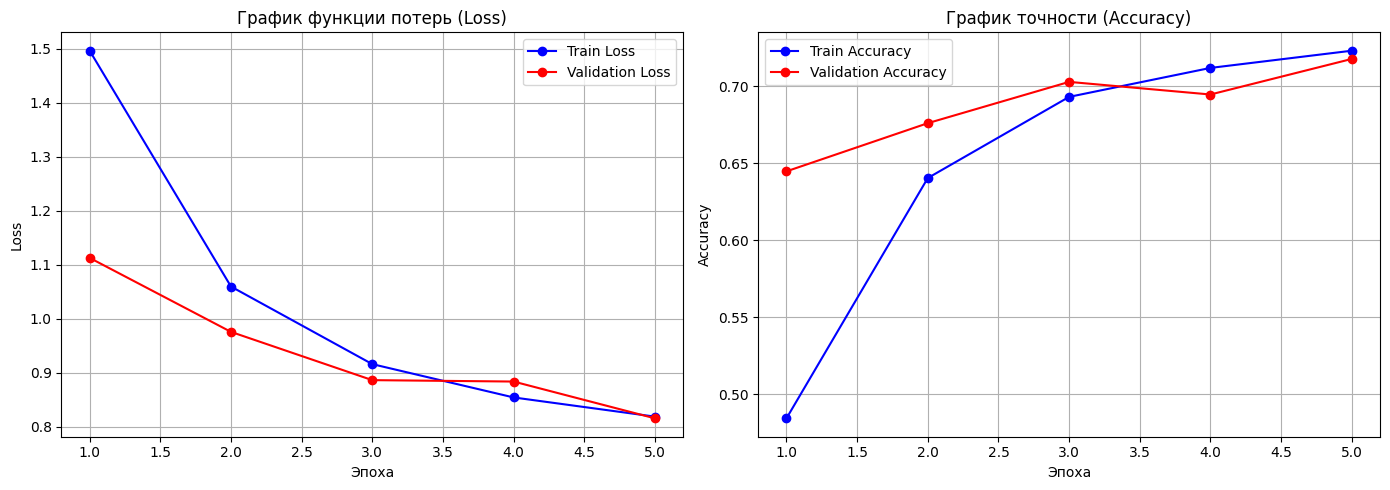

In [20]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
from PIL import ImageFile
import matplotlib.pyplot as plt

ImageFile.LOAD_TRUNCATED_IMAGES = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


data_dir = 'data/mushrooms/Mushrooms'
train_transforms = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
val_transforms = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class SafeImageFolder(datasets.ImageFolder):
    def __getitem__(self, index):
        while True:
            try:
                path, target = self.samples[index]
                sample = self.loader(path)
                if self.transform is not None: sample = self.transform(sample)
                if self.target_transform is not None: target = self.target_transform(target)
                return sample, target
            except Exception:
                index = torch.randint(0, len(self.samples), (1,)).item()

full_dataset = SafeImageFolder(root=data_dir)
class_names = full_dataset.classes
num_classes = len(class_names)

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])
train_dataset.dataset.transform = train_transforms
val_dataset.dataset.transform = val_transforms

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)


model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model.parameters(): param.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)


train_loss_history = []
val_loss_history = []
train_acc_history = []
val_acc_history = []

num_epochs = 5
print("Начинаем обучение...")

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct, total = 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = correct / total
    train_loss_history.append(train_loss)
    train_acc_history.append(train_acc)

    model.eval()
    val_running_loss = 0.0
    val_correct, val_total = 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = val_correct / val_total
    val_loss_history.append(val_loss)
    val_acc_history.append(val_acc)

    print(f"Эпоха {epoch+1}/{num_epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(14, 5))

#loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_loss_history, label='Train Loss', marker='o', color='blue')
plt.plot(epochs_range, val_loss_history, label='Validation Loss', marker='o', color='red')
plt.title('График функции потерь (Loss)')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

#accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_acc_history, label='Train Accuracy', marker='o', color='blue')
plt.plot(epochs_range, val_acc_history, label='Validation Accuracy', marker='o', color='red')
plt.title('График точности (Accuracy)')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

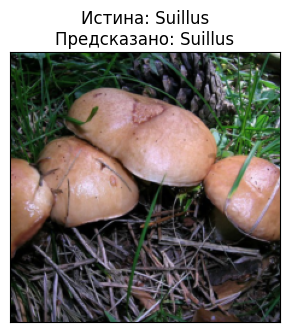

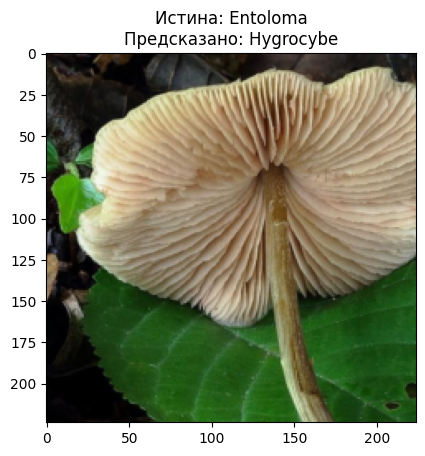

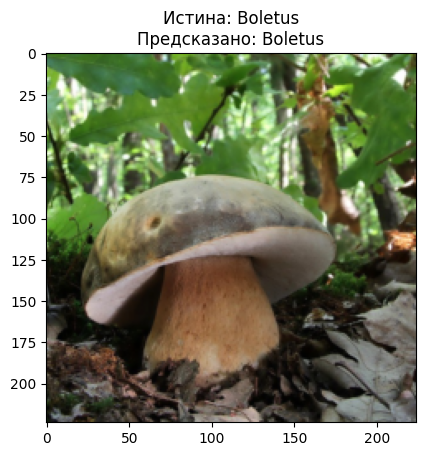

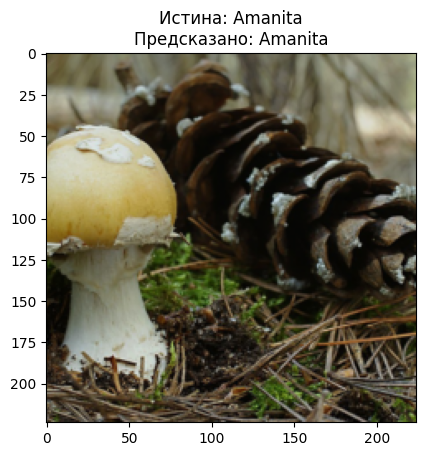

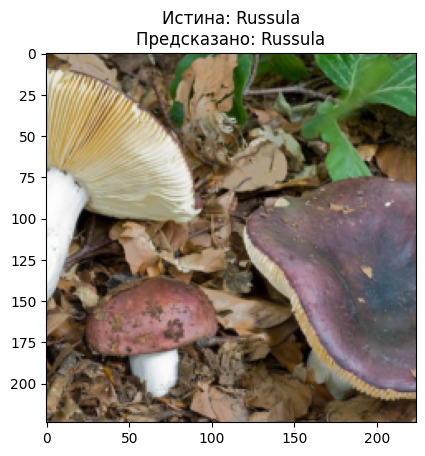

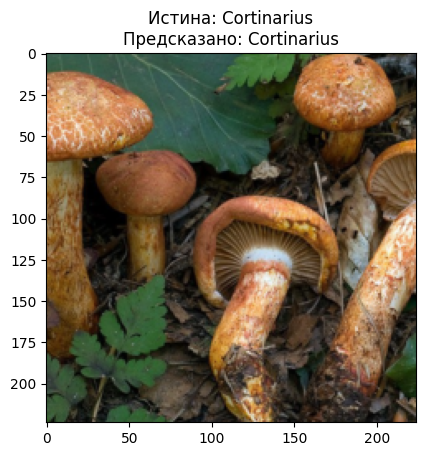

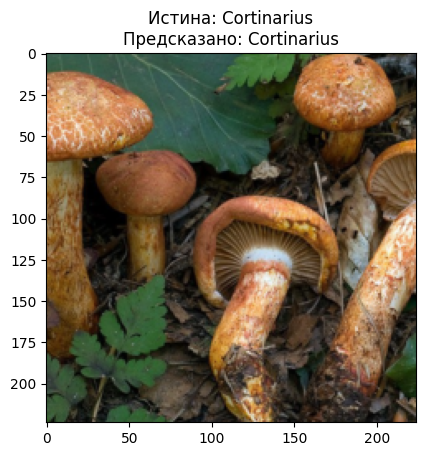

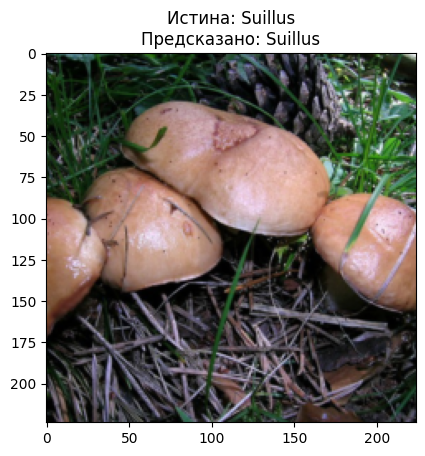

<Figure size 640x480 with 0 Axes>

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import random

def imshow(inp, title=None):
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)

val_batches = list(val_loader)

random_batch_idx = random.randint(0, len(val_batches) - 1)
images, labels = val_batches[random_batch_idx]

images, labels = images.to(device), labels.to(device)

model.eval()
with torch.no_grad():
    outputs = model(images)
    _, preds = torch.max(outputs, 1)


fig = plt.figure(figsize=(16, 8))
for i in range(8):
    idx = random.randint(0, len(images) - 1)
    ax = fig.add_subplot(2, 4, i+1, xticks=[], yticks=[])

    true_label = class_names[labels[idx]]
    pred_label = class_names[preds[idx]]

    imshow(images.cpu()[idx], title=f"Истина: {true_label}\nПредсказано: {pred_label}")


plt.tight_layout()
plt.show()